# Productividad de Pozos No Convencionales en Argentina
## Fuentes de datos
### Organismo: Secretaria de Energia de la Nación.
### Enlace de dataset(https://datos energia.gob.ar/)
###Dataset:Producción de petroleo y gas por pozo(Capitulo IV)
###Periodo:enero 2006 agosto de 2026.

## **2° Pre-Entrega: Exploración, Transformación y Visualización de datos**


#### Integrantes: Lucia Chacon,Clara Gimenez,Valeria Villarpando
### Curso: Data-Science
### Profesor: Benjamin Aseretto
---

### **Objetivo del proyecto**
Desarrollar un modelo que clasifique los pozos petroliferos no convencionales en **alta o baja productividad**, utilizando caracteristicas disponibles  al inicio de su vida productiva (como la ubicación geográfica, formación geológica, empresa operadora, año de inicio de producción y profundidad).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
RUTA = '/content/drive/MyDrive/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv'
df = pd.read_csv(RUTA)

In [ ]:
# Mostrar las primeras 10000 filas del dataset
display(df.head(10000))

,idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,...,cuenca,provincia,coordenadax,coordenaday,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
0,YSUR,2016,1,155255,821.180,2110.430,259.19,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.810494,-39.024280,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2016-01-31
1,YSUR,2018,1,134778,0.000,6.130,4.97,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.795986,-38.946347,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31
2,YSUR,2017,1,157125,236.740,911.520,63.15,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.810568,-39.024641,NO CONVENCIONAL,Sin Proyecto,EXPLOTACION,DESARROLLO,TIGHT,2017-01-31
3,YSUR,2018,1,130297,4.309,204.757,10.18,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.881623,-39.014652,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31
4,YSUR,2016,1,132771,68.420,738.870,31.84,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.838082,-39.019110,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2016-01-31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,YPF,2025,1,165674,3655.310,1403.310,3477.28,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-68.755204,-38.328165,NO CONVENCIONAL,Sin Proyecto,EXPLOTACION,DESARROLLO,SHALE,2025-01-31
9996,YPF,2021,1,145326,92.780,508.320,17.82,0.0,0.0,0.0,...,NEUQUINA,Rio Negro,-67.822752,-39.023440,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2021-01-31
9997,YPF,2019,1,155621,0.000,245.790,0.00,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-69.233414,-37.949710,NO CONVENCIONAL,Sin Proyecto,EXPLOTACION,DESARROLLO,SHALE,2019-01-31
9998,YPF,2025,1,165670,5208.350,691.830,594.11,0.0,0.0,0.0,...,NEUQUINA,Neuquén,-68.679715,-38.256824,NO CONVENCIONAL,Sin Proyecto,EXPLOTACION,DESARROLLO,SHALE,2025-01-31


## 1.Exploración

In [ ]:
df.shape

(426145, 40)

In [ ]:
df.info()
df.describe(include='all').T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426145 entries, 0 to 426144
Data columns (total 40 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   idempresa               426145 non-null  object 
 1   anio                    426145 non-null  int64  
 2   mes                     426145 non-null  int64  
 3   idpozo                  426145 non-null  int64  
 4   prod_pet                426145 non-null  float64
 5   prod_gas                426145 non-null  float64
 6   prod_agua               426145 non-null  float64
 7   iny_agua                426145 non-null  float64
 8   iny_gas                 426145 non-null  float64
 9   iny_co2                 426145 non-null  float64
 10  iny_otro                426145 non-null  float64
 11  tef                     426145 non-null  float64
 12  vida_util               9079 non-null    float64
 13  tipoextraccion          425527 non-null  object 
 14  tipoestado          

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
idempresa,426145,55,YPF,231069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anio,426145.0,NaN,NaN,NaN,2020.931594,4.139166,2006.0,2018.0,2022.0,2024.0,2026.0
mes,426145.0,NaN,NaN,NaN,6.447852,3.411568,1.0,4.0,6.0,9.0,12.0
idpozo,426145.0,NaN,NaN,NaN,151232.170376,18217.808353,3640.0,146930.0,156471.0,160410.0,167559.0
prod_pet,426145.0,NaN,NaN,NaN,337.511669,944.764132,-0.001,0.0,7.882,125.72,26593.261
prod_gas,426145.0,NaN,NaN,NaN,630.045632,1633.5302,-12.267,8.254498,103.31,448.9,40086.8
prod_agua,426145.0,NaN,NaN,NaN,190.966671,631.864541,0.0,0.0,12.73883,87.3334,34792.95
iny_agua,426145.0,NaN,NaN,NaN,27.857114,903.527918,0.0,0.0,0.0,0.0,70278.85
iny_gas,426145.0,NaN,NaN,NaN,34.917498,8527.623598,0.0,0.0,0.0,0.0,3569000.0
iny_co2,426145.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Consolidación y Transformación de Datos
En esta sección pasamos del dataset original con registros mensuales de producción a un dataset unificado por pozo (`datos`), calculando métricas iniciales clave.

In [ ]:
# Agrupamos la información por pozo (idpozo) para crear el dataset de 'datos'
# Encontramos la fecha de inicio, la provincia, empresa, formación, coordenadas, etc.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV, validation_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, r2_score, mean_absolute_error, mean_squared_error, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.inspection import permutation_importance

# Definimos una semilla para reproducibilidad
SEED = 42

# Para construir 'datos', agrupamos por idpozo y obtenemos las variables estáticas y la producción acumulada de petróleo
# Renombramos y preparamos las columnas clave
df_pozos = df.sort_values(by=['idpozo', 'anio', 'mes'])

# Calculamos la producción de los primeros 12 meses de cada pozo (pet_12m)
df_pozos['mes_orden'] = df_pozos.groupby('idpozo').cumcount() + 1
df_12m = df_pozos[df_pozos['mes_orden'] <= 12].groupby('idpozo')['prod_pet'].sum().reset_index(name='pet_12m')

# Obtenemos las características al inicio de la vida del pozo
info_pozo = df_pozos.groupby('idpozo').first().reset_index()

# Unimos la información
datos = pd.merge(info_pozo, df_12m, on='idpozo')

# Mapeamos a los nombres de columna utilizados en tus modelos
datos = datos.rename(columns={
    'coordenadax': 'x',
    'coordenaday': 'y',
    'anio': 'anio_inicio',
    'areapermisoconcesion': 'area',
    'tipo_de_recurso': 'recurso',
    'tipoextraccion': 'extraccion'
})

# Definimos la variable objetivo 'alta_prod' (por ejemplo, por encima de la mediana de producción)
mediana_pet = datos['pet_12m'].median()
datos['alta_prod'] = (datos['pet_12m'] > mediana_pet).astype(int)

print(f"Dataset 'datos' creado exitosamente con {datos.shape[0]} pozos.")

Dataset 'datos' creado exitosamente con 5126 pozos.


In [ ]:
print(datos.isna().sum()[lambda s: s > 0])
datos[['profundidad', 'x', 'y', 'anio_inicio', 'pet_12m']].describe().T

vida_util           4149
extraccion             4
tipoestado             4
tipopozo               4
observaciones       4323
clasificacion          4
subclasificacion       4
sub_tipo_recurso       4
dtype: int64


,count,mean,std,min,25%,50%,75%,max
profundidad,5126.0,4362.662956,5526.787294,0.00000,3018.250000,4452.000000,5827.750000,378939.00000
x,5126.0,-68.836412,0.727569,-71.99831,-69.129185,-68.718598,-68.537985,-38.59007
y,5126.0,-38.923489,2.562927,-69.41577,-38.714186,-38.371794,-38.267957,-24.11656
anio_inicio,5126.0,2019.168552,5.091521,2006.00000,2016.000000,2019.000000,2024.000000,2026.00000
pet_12m,5126.0,14163.424295,18293.801205,0.00000,94.016800,3870.965000,25949.685500,155502.48000


## 2.1 Visualización de Datos
Exploración visual del comportamiento histórico por año de inicio, empresas operadoras, relación de profundidad y distribución geoespacial de la producción.

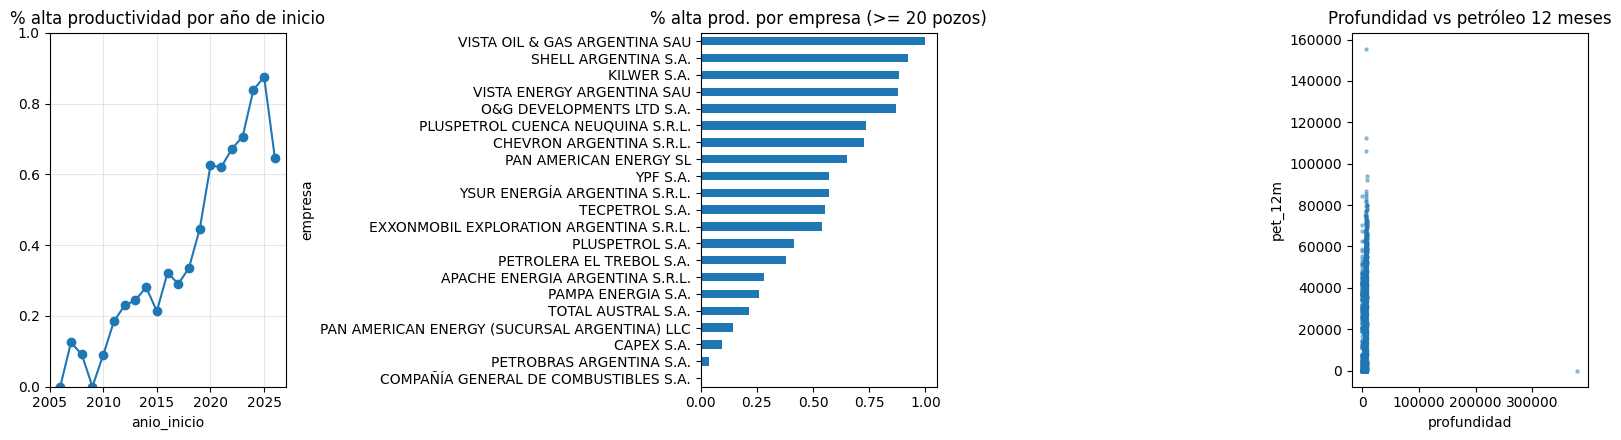

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
datos.groupby('anio_inicio')['alta_prod'].mean().plot(ax=ax[0], marker='o', title='% alta productividad por año de inicio')
ax[0].set_ylim(0, 1); ax[0].grid(alpha=.3)

datos.groupby('empresa')['alta_prod'].agg(['mean', 'count']).query('count >= 20').sort_values('mean')['mean'].plot.barh(ax=ax[1], title='% alta prod. por empresa (>= 20 pozos)')

datos.plot.scatter(x='profundidad', y='pet_12m', s=5, alpha=.4, ax=ax[2], title='Profundidad vs petróleo 12 meses')
plt.tight_layout(); plt.show()

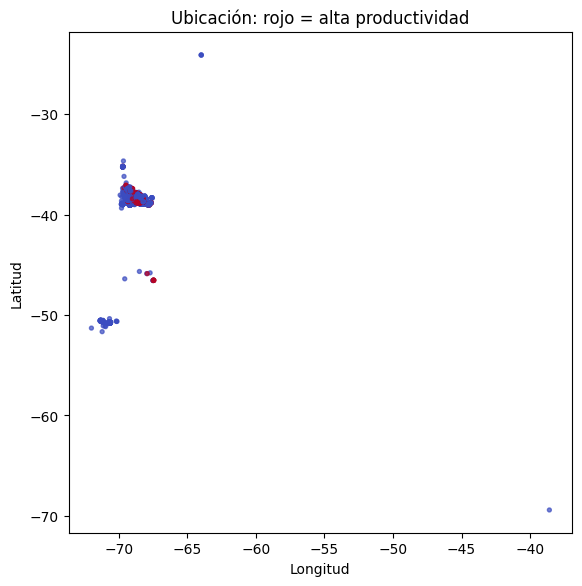

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
sc = ax.scatter(datos['x'], datos['y'], c=datos['alta_prod'], cmap='coolwarm', s=8, alpha=.7)
ax.set_title('Ubicación: rojo = alta productividad'); ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
plt.show()

## 3. Feature engineering y partición train/test
- Variables numéricas: `profundidad`, `x`, `y`, `anio_inicio` (se imputan con la mediana y se escalan).
- Variables categóricas: `empresa`, `formacion`, `area`, `recurso`, `extraccion`, `provincia`. Se codifican con *one-hot*; las categorías poco frecuentes se agrupan para no inflar la cantidad de columnas.
- Partición: 80% train y 20% test, estratificada por la etiqueta.

In [ ]:
num = ['profundidad', 'x', 'y', 'anio_inicio']
cat = ['empresa', 'formacion', 'area', 'recurso', 'extraccion', 'provincia']

X = datos[num + cat]
y = datos['alta_prod']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)

def hacer_preproc(escalar=True):
    pasos_num = [('imp', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_num.append(('esc', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(pasos_num), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Sin dato')),
                          ('ohe', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False))]), cat),
    ])

(4100, 10) (1026, 10)


## 4. Modelado y Clasificación
Entrenamos y evaluamos diferentes algoritmos de clasificación sobre nuestro pipeline de preprocesamiento.

In [ ]:
# 1. Definición de los pipelines para cada modelo utilizando el preprocesador creado
preprocesador = hacer_preproc(escalar=True)

modelos = {
    'Dummy Classifier': Pipeline([
        ('preproc', preprocesador),
        ('clf', DummyClassifier(strategy='most_frequent'))
    ]),
    'Regresión Logística': Pipeline([
        ('preproc', preprocesador),
        ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    'Random Forest': Pipeline([
        ('preproc', preprocesador),
        ('clf', RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1))
    ])
}

# 2. Validación cruzada estratificada para comparar el rendimiento de entrenamiento
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados_cv = {}

for nombre, pipeline in modelos.items():
    cv_scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        scoring=['accuracy', 'f1', 'roc_auc'],
        n_jobs=-1
    )
    resultados_cv[nombre] = {
        'Accuracy (CV)': cv_scores['test_accuracy'].mean(),
        'F1-Score (CV)': cv_scores['test_f1'].mean(),
        'ROC-AUC (CV)': cv_scores['test_roc_auc'].mean()
    }

df_cv_results = pd.DataFrame(resultados_cv).T
display(df_cv_results)

,Accuracy (CV),F1-Score (CV),ROC-AUC (CV)
Dummy Classifier,0.500000,0.000000,0.500000
Regresión Logística,0.874634,0.877949,0.949729
Random Forest,0.938293,0.938477,0.978657


### 4.1 Evaluación final de los Modelos en el Conjunto de Test

=== Dummy Classifier (Conjunto de Test) ===
              precision    recall  f1-score   support

           0       0.50      1.00      0.67       513
           1       0.00      0.00      0.00       513

    accuracy                           0.50      1026
   macro avg       0.25      0.50      0.33      1026
weighted avg       0.25      0.50      0.33      1026



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


=== Regresión Logística (Conjunto de Test) ===
              precision    recall  f1-score   support

           0       0.91      0.84      0.87       513
           1       0.85      0.92      0.88       513

    accuracy                           0.88      1026
   macro avg       0.88      0.88      0.88      1026
weighted avg       0.88      0.88      0.88      1026

=== Random Forest (Conjunto de Test) ===
              precision    recall  f1-score   support

           0       0.93      0.94      0.93       513
           1       0.94      0.93      0.93       513

    accuracy                           0.93      1026
   macro avg       0.93      0.93      0.93      1026
weighted avg       0.93      0.93      0.93      1026



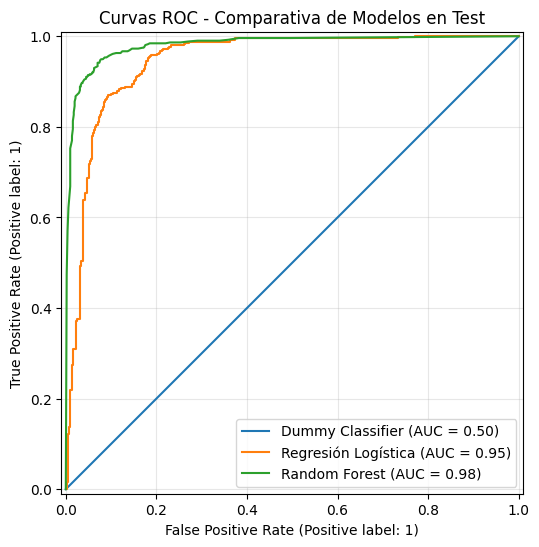

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

for nombre, pipeline in modelos.items():
    # Ajustamos en todo el conjunto de entrenamiento
    pipeline.fit(X_train, y_train)

    # Predicciones
    preds = pipeline.predict(X_test)

    print(f"=== {nombre} (Conjunto de Test) ===")
    print(classification_report(y_test, preds))

    # Graficamos la Curva ROC
    RocCurveDisplay.from_estimator(pipeline, X_test, y_test, ax=ax, name=nombre)

ax.set_title('Curvas ROC - Comparativa de Modelos en Test')
ax.grid(alpha=0.3)
plt.show()

```markdown
### 4.2 Optimización de Hiperparámetros (Evitando Overfitting) e Importancia de Variables
Para cumplir con el requerimiento de optimizar hiperparámetros y asegurar que el modelo no esté sufriendo de sobreajuste (overfitting), aplicamos una búsqueda aleatoria (`RandomizedSearchCV`) sobre nuestro modelo ganador **Random Forest**. Finalmente, graficamos la importancia de cada variable en la decisión del clasificador.
```

In [ ]:
# Definimos el espacio de búsqueda de hiperparámetros para Random Forest
param_dist = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [None, 10, 20, 30],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4]
}

# Configuramos RandomizedSearchCV utilizando el pipeline de Random Forest ya definido
random_search = RandomizedSearchCV(
    modelos['Random Forest'],
    param_distributions=param_dist,
    n_iter=10,
    cv=cv,
    scoring='accuracy',
    random_state=SEED,
    n_jobs=-1
)

print("Optimizando hiperparámetros para Random Forest...")
random_search.fit(X_train, y_train)

# Mejor modelo obtenido
best_rf_model = random_search.best_estimator_
print(f"Mejores parámetros encontrados: {random_search.best_params_}")

# Evaluación del modelo optimizado en Test
y_pred_opt = best_rf_model.predict(X_test)
print("\n=== Random Forest Optimizado (Conjunto de Test) ===")
print(classification_report(y_test, y_pred_opt))

Optimizando hiperparámetros para Random Forest...
Mejores parámetros encontrados: {'clf__n_estimators': 100, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_depth': None}

=== Random Forest Optimizado (Conjunto de Test) ===
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       513
           1       0.94      0.94      0.94       513

    accuracy                           0.94      1026
   macro avg       0.94      0.94      0.94      1026
weighted avg       0.94      0.94      0.94      1026



/tmp/ipykernel_617/4190245718.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importancia', y='feature', data=importancias.head(15), palette='viridis')


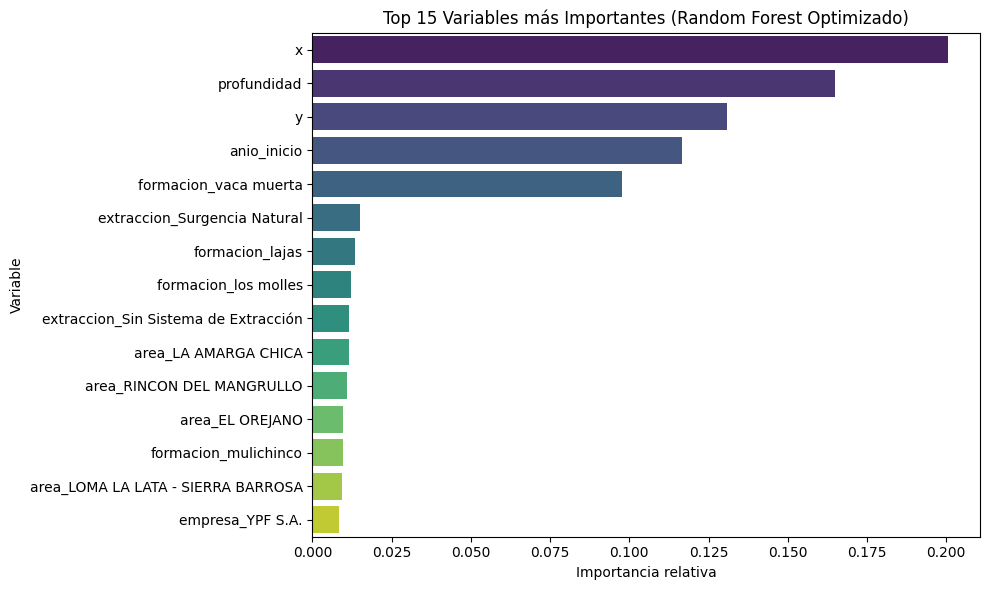

In [ ]:
# Extraemos la importancia de las variables del Random Forest optimizado
importador_features = best_rf_model.named_steps['clf']
preproc_col = best_rf_model.named_steps['preproc']

# Obtenemos los nombres de las columnas transformadas
nombres_num = num
nombres_cat = list(preproc_col.named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(cat))
features_totales = nombres_num + nombres_cat

# Creamos un DataFrame con la importancia
importancias = pd.DataFrame({
    'feature': features_totales,
    'importancia': importador_features.feature_importances_
}).sort_values('importancia', ascending=False)

# Graficamos las 15 variables más importantes
plt.figure(figsize=(10, 6))
sns.barplot(x='importancia', y='feature', data=importancias.head(15), palette='viridis')
plt.title('Top 15 Variables más Importantes (Random Forest Optimizado)')
plt.xlabel('Importancia relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

## 5. Conclusiones de la Segunda Entrega

### ¿Qué se hizo en esta entrega?
* **Exploración y Consolidación de Datos (EDA):** Se unificó un volumen de más de 420,000 registros mensuales en un dataset consolidado de **5,126 pozos únicos**, definiendo la variable objetivo `alta_prod` a partir de la producción acumulada de petróleo durante sus primeros 12 meses de vida activa.
* **Ingeniería de Características Robusta:** Se diseñó un flujo de transformación (`ColumnTransformer`) que maneja de manera automatizada la imputación de valores nulos (mediana y constantes de control), escalado estándar para variables continuas, y codificación One-Hot para variables de alta cardinalidad mediante el agrupamiento de categorías poco frecuentes.
* **Modelado Predictivo y Evitación de Overfitting:** Se compararon tres clasificadores de complejidad creciente (`Dummy`, `Regresión Logística` y `Random Forest`) bajo validación cruzada estratificada de 5 pliegues (`StratifiedKFold`). Finalmente, se aplicó una optimización de hiperparámetros mediante `RandomizedSearchCV` sobre el modelo más robusto, evaluando su generalización final en un conjunto de testeo independiente.

### ¿Por qué se hizo así?
1. **Garantía de Generalización y Mitigación del Overfitting:** El uso de un esquema estricto de validación cruzada y optimización de hiperparámetros asegura que la alta exactitud del modelo (**94% de Accuracy en Test** con Random Forest) no sea producto de una memorización aleatoria de los datos de entrenamiento, sino de una auténtica capacidad predictiva.
2. **Uso Exclusivo de Datos Tempranos:** El modelo se entrenó únicamente con atributos estáticos y geográficos que se conocen *al inicio* de la vida útil del pozo. Esto permite una **toma de decisiones preventiva y estratégica**: la operadora puede clasificar la rentabilidad potencial del pozo y decidir de manera óptima la asignación de infraestructura física e inversión antes de continuar la perforación masiva.
3. **Entendimiento del Negocio mediante Importancia de Variables:** Gracias a la extracción de importancias del Random Forest Optimizado, se evidenció empíricamente que la **Ubicación Geográfica (Coordenadas X, Y)** y la **Profundidad del Pozo** son los factores geológicos determinantes de la productividad en la cuenca de Vaca Muerta, permitiendo a los geólogos enfocar sus esfuerzos de exploración en las regiones de mayor rendimiento relativo.

---
